# 04 Adversarial robustness of the semantic receiver
Run **after** notebooks 01 and 02 (needs `loc_v2.json`, `heatmaps_v2.npy`, the localizer ensemble and the classifier). Notebook 03 is not required.

## Threat model
| Attacker | Position | Knowledge | Capability | Where it is simulated |
|---|---|---|---|---|
| **A1 pixel, white-box** | in transit / compromised relay | full receiver (weights, crop rule) | L∞ perturbation ε ≤ 8/255, 8-bit | Part A: `clf`, `loc` |
| **A2 pixel, end-to-end** | same | full receiver, **including the localizer → crop → classifier chain** | 2-stage PGD: move the crop, then attack the new crop | Part A: `e2e` |
| **A3 pixel, transfer** | same | surrogate only (single localizer seed / other classifier) | craft on surrogate, evaluate on the real receiver | Part A: `transfer` |
| **A4 adaptive** | same | full receiver **and** its blur defence | gradient through the differentiable blur | Part A: `adaptive` |
| **A5 tag eavesdropper** | observes packet headers | priority tags only (no pixels) | reads where the lesion is, erases / forges tags | Part B |
| **A6 combined** | pixel attack and packet loss together | full | e2e PGD + 30 % loss, uniform vs priority network | Part C |

**Metrics:** robust AUC (patient-level bootstrap 95 % CI), attack success rate (ASR = correct→wrong among clean-correct images),
malignant-missed rate (MMR = malignant predicted benign), localization hit rate, PSNR / SSIM of the perturbation.

In [15]:
import os, sys, importlib
p = "/content/drive/MyDrive/mammo_semcom/src/attack_v2.py"
print("size:", os.path.getsize(p), "bytes | has attack_e2e:", "def attack_e2e" in open(p).read())

size: 6322 bytes | has attack_e2e: True


In [16]:
import sys
sys.modules.pop("src.attack_v2", None)
from src.attack_v2 import attack, attack_e2e, blur_t, perturb_quality, public_tags, tag_attack
print("import ok")

import ok


In [17]:
from google.colab import drive; drive.mount("/content/drive")
import glob, os, sys, json
hits = glob.glob("/content/drive/MyDrive/mammo_semcom/**/src/config.py", recursive=True)
CODE_DIR = os.path.dirname(os.path.dirname(hits[0])); WORK_DIR = "/content/drive/MyDrive/mammo_semcom_work"
sys.path.insert(0, CODE_DIR); print("code:", CODE_DIR)
import numpy as np, pandas as pd, cv2, torch, matplotlib.pyplot as plt
from src.config import Cfg
from src import data
from src.train import to01, DEVICE
from src.metrics import auc_safe
from src.channel import apply_loss
from src.pipeline import diagnose_all
from src.train_v2 import load_classifier_v2, load_localizer_v2, ReceiverV2
from src.tx_v2 import importance_sets, deliver
from src.attack_v2 import attack, attack_e2e, blur_t, perturb_quality, public_tags, tag_attack

N_PIXEL, N_TAG, BS, STEPS = 120, 100, 4, 10       # dry run: N_PIXEL=16, N_TAG=16, STEPS=3. Lower BS if the GPU runs out of memory.
EPS = (1, 2, 4, 8)                                 # in 1/255 units
K_TAG, LOSS_P, N_BOOT = (4, 16), (0., .3), 200
M_SEEDS = 3                                        # use the same number of seeds as in notebook 01

cfg = Cfg(work_dir=WORK_DIR).ensure()
images, masks, images_df, abn_df = data.load_cache(cfg)
heat = np.load(cfg.path("cache", "heatmaps_v2.npy"), mmap_mode="r")
lm = json.load(open(cfg.path("models", "loc_v2.json")))
localizers = [load_localizer_v2(cfg, f"v2_s{s}", lm["act"]) for s in range(M_SEEDS)]
clf, cmeta = load_classifier_v2(cfg); THR = cmeta["thr"]
for mod in (*localizers, clf):
    for p in mod.parameters(): p.requires_grad_(False)
receiver = ReceiverV2(cfg, localizers, clf, sigma=lm["sigma"])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
code: /content/drive/MyDrive/mammo_semcom


In [18]:
# ---- data: test images (patient-level split, mixed-label images excluded), subset selected without looking at results
te = images_df[(images_df.split == "test") & (~images_df.mixed)]
pidc = next((c for c in ("pid", "patient_id") if c in te.columns), None)
te = te.sample(n=min(max(N_PIXEL, N_TAG), len(te)), random_state=cfg.seed).sort_index()
ids = te.img_idx.values; y = te.label.values.astype(int); N = len(ids)
pid = pd.factorize(te[pidc])[0] if pidc else np.arange(N)
img01 = np.stack([to01(images[i]) for i in ids]); M = masks[ids] > 0
H = np.stack([np.asarray(heat[i], np.float32) for i in ids])
ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (49, 49)); gt_dil = [cv2.dilate(m.astype(np.uint8), ker) > 0 for m in M]
T = lambda a: torch.from_numpy(np.ascontiguousarray(a)).float()[:, None].to(DEVICE)
denoise = lambda a: np.stack([cv2.GaussianBlur(x, (0, 0), 1.0) for x in a])      # receiver defence = blur_t(sigma=1)

def ev(imgs, defence=False):
    """per-image receiver outputs for a set of (possibly attacked / damaged) images"""
    r = diagnose_all(receiver, denoise(imgs) if defence else imgs)
    hit = np.array([gt_dil[i][int(round(r["cy"][i])), int(round(r["cx"][i]))] for i in range(len(imgs))])
    return dict(p=r["p"], hit=hit)

def boot(fn, idx, n=N_BOOT, seed=0):
    """patient-level bootstrap 95 % CI of fn(index array)"""
    rng = np.random.default_rng(seed); up = np.unique(pid[idx]); g = {u: idx[pid[idx] == u] for u in up}; v = []
    for _ in range(n):
        s = np.concatenate([g[u] for u in rng.choice(up, len(up))]); v.append(fn(s))
    return np.nanpercentile(v, [2.5, 97.5])

ALL = np.arange(N)
clean = ev(img01); clean_ok = (clean["p"] >= THR) == y
def summ(r, idx=ALL):
    pr = r["p"] >= THR; ok = clean_ok[idx]
    auc = auc_safe(y[idx], r["p"][idx]); lo, hi = boot(lambda s: auc_safe(y[s], r["p"][s]), idx)
    return dict(AUC=auc, AUC_lo=lo, AUC_hi=hi, ACC=float((pr[idx] == y[idx]).mean()),
                ASR=float((pr[idx][ok] != y[idx][ok]).mean()) if ok.any() else np.nan,
                MMR=float((~pr[idx][y[idx] == 1]).mean()), loc_hit=float(r["hit"][idx].mean()))
print(f"images: {N} (malignant {y.sum()}), patients: {len(np.unique(pid))}"); print("clean:", {k: round(v, 3) for k, v in summ(clean).items()})

images: 120 (malignant 47), patients: 102
clean: {'AUC': 0.695, 'AUC_lo': np.float64(0.606), 'AUC_hi': np.float64(0.797), 'ACC': 0.575, 'ASR': 0.0, 'MMR': 0.34, 'loc_hit': 0.492}


## Part A. Pixel attacks (PGD, L∞, 8-bit)
`clf` attacks the classifier at the clean crop, `loc` the localizer ensemble (moves the heat-map peak), `e2e` moves the crop first and then attacks the classifier on the new crop,
`transfer` crafts on a surrogate (localizer seed 0 only) and is evaluated on the full ensemble, `adaptive` = attack through the receiver's blur defence.

In [ ]:
H_t = H; _r = diagnose_all(receiver, img01); c0 = np.stack([_r["cy"], _r["cx"]], 1)      # crop centres the attacker assumes
def craft(kind, e, pre=None, n=N_PIXEL):
    out = []
    for s in range(0, n, BS):
        sl = slice(s, min(s + BS, n)); x, yy, m = T(img01[sl]), y[sl], T(M[sl])
        if kind == "e2e": a = attack_e2e(receiver, x, yy, m, cfg, e / 255, STEPS)
        elif kind == "transfer": a = attack("loc", x, yy, None, None, m, [localizers[0]], clf, cfg, e / 255, STEPS)
        else: a = attack(kind, x, yy, T(H_t[sl]), c0[sl], m, localizers, clf, cfg, e / 255, STEPS, pre=pre)
        out.append(a[:, 0].cpu().numpy())
    return np.concatenate(out)

IDX = np.arange(min(N_PIXEL, N)); adv_cache = {}
rows = []
for d in (False, True):
    rows.append(dict(attack="none", eps=0, defence="blur" if d else "none", **summ(ev(img01, d), IDX)))
BLUR = lambda t: blur_t(t, 1.0)
for kind in ("clf", "loc", "e2e", "transfer", "adaptive_clf", "adaptive_loc"):
    for e in EPS:
        adaptive = kind.startswith("adaptive")
        adv = craft(kind.split("_")[1] if adaptive else kind, e, BLUR if adaptive else None); adv_cache[(kind, e)] = adv
        ps, ss = perturb_quality(img01[:len(adv)], adv)
        for d in ((True,) if adaptive else (False, True)):
            rows.append(dict(attack=kind, eps=e, defence="blur" if d else "none", PSNR=ps, SSIM=ss, **summ(ev(adv, d), IDX)))
        print("done", kind, e)
A_res = pd.DataFrame(rows); A_res.to_csv(cfg.path("results", "adversarial_pixel_v2.csv"), index=False); display(A_res.round(3))

done clf 1
done clf 2
done clf 4
done clf 8
done loc 1
done loc 2
done loc 4
done loc 8
done e2e 1
done e2e 2
done e2e 4
done e2e 8
done transfer 1
done transfer 2
done transfer 4
done transfer 8
done adaptive_clf 1
done adaptive_clf 2
done adaptive_clf 4
done adaptive_clf 8
done adaptive_loc 1
done adaptive_loc 2
done adaptive_loc 4


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for kind in ("clf", "loc", "e2e", "transfer"):
    s = A_res[(A_res.attack.isin([kind, "none"])) & (A_res.defence == "none")].sort_values("eps")
    ax[0].plot(s.eps, s.AUC, "o-", label=kind); ax[1].plot(s.eps, s.loc_hit, "o-", label=kind)
for kind, lab in (("e2e", "e2e, blur defence"), ("adaptive_clf", "adaptive clf"), ("adaptive_loc", "adaptive loc")):
    s = A_res[(A_res.attack.isin([kind, "none"])) & (A_res.defence == "blur")].sort_values("eps")
    ax[2].plot(s.eps, s.AUC, "o-", label=lab)
for a, t in zip(ax, ("robust AUC (no defence)", "localization hit rate (no defence)", "robust AUC (blur defence)")):
    a.set_title(t); a.set_xlabel("ε (/255)"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(cfg.path("results", "adversarial_pixel_v2.png"), dpi=130); plt.show()

## Part B. Tag attacks and tag defences (the semantic-specific threat)
The priority tags are public: they tell the network which blocks matter, and therefore also tell an eavesdropper **where the lesion is**.
* **leakage**: how often the single highest-tagged block lies on the lesion, *without looking at any pixel*.
* **attacks**: `erase` (delete the k highest-tagged blocks if tags are readable, else k random blocks), `invert` (reverse the ranking), `inject` (tag k background blocks as top priority).
* **defences**: `decoy` (extra background blocks tagged top priority), `random` (noise added to the ranking), `encrypt` (tags authenticated and unreadable: attacker is blind and cannot forge).
Network loss (30 %) is applied on top. `uniform` = no tags at all (the old non-semantic transmission).

In [ ]:
NT = min(N_TAG, N); IT = np.arange(NT)
imps = importance_sets(cfg, img01[:NT], list(H[:NT]), clf)["clinical"]
lesion_blocks = [(im >= 2) for im in imps]

def leak(defence, seed=0):
    rng = np.random.default_rng(seed); h = []
    for i in range(NT):
        t = public_tags(imps[i], defence, rng); f = t.ravel(); cand = np.flatnonzero(f == f.max()); j = rng.choice(cand)
        cy_, cx_ = divmod(j, t.shape[1]); h.append(gt_dil[i][min(cy_ * cfg.block + cfg.block // 2, gt_dil[i].shape[0] - 1), min(cx_ * cfg.block + cfg.block // 2, gt_dil[i].shape[1] - 1)])
    return float(np.mean(h))
L_res = pd.DataFrame([dict(tag_defence=d, top_tag_on_lesion=leak(d)) for d in ("none", "decoy", "random")])
L_res.to_csv(cfg.path("results", "tag_leakage_v2.csv"), index=False); display(L_res.round(3))

In [22]:
def run_tag(strategy, defence, attack_kind, k, p, seed=0):
    dmg, les = [], []
    for i in range(NT):
        rng = np.random.default_rng(seed + i)
        enc = defence == "encrypt"
        tags = public_tags(imps[i], "none" if enc else defence, rng)
        kind = "none" if (enc and attack_kind in ("invert", "inject")) else attack_kind      # authenticated tags: forgery rejected
        used, erased = tag_attack(kind, imps[i], tags, k, rng, reads_tags=(not enc) and strategy != "uniform")
        used = np.where(imps[i] >= 0, used, -1.)
        lost, _ = deliver(imps[i] if strategy == "uniform" else used, strategy, dict(p=p), rng, cfg.burst_len)
        if erased is not None: lost = lost | erased
        dmg.append(apply_loss(img01[i], lost, cfg.block, cfg.recon)[0]); les.append(float((lost & lesion_blocks[i]).sum() / max(lesion_blocks[i].sum(), 1)))
    r = ev(np.stack(dmg)); r["les_lost"] = float(np.mean(les)); return r

rows = []
configs = [("uniform", "none", a) for a in ("none", "erase")]
configs += [("proposed", d, a) for d in ("none", "decoy", "random", "encrypt") for a in ("none", "erase", "invert", "inject")]
for strat, d, a in configs:
    for p in LOSS_P:
        for k in (K_TAG if a != "none" else (0,)):
            r = run_tag(strat, d, a, k, p)
            rows.append(dict(strategy=strat, tag_defence=d, attack=a, k=k, loss=p, lesion_blocks_lost=r["les_lost"], **summ(r, IT)))
    print("done", strat, d, a)
B_res = pd.DataFrame(rows); B_res.to_csv(cfg.path("results", "adversarial_tags_v2.csv"), index=False); display(B_res.round(3))

done uniform none none
done uniform none erase
done proposed none none
done proposed none erase
done proposed none invert
done proposed none inject
done proposed decoy none
done proposed decoy erase
done proposed decoy invert
done proposed decoy inject
done proposed random none
done proposed random erase
done proposed random invert
done proposed random inject
done proposed encrypt none
done proposed encrypt erase
done proposed encrypt invert
done proposed encrypt inject


,strategy,tag_defence,attack,k,loss,lesion_blocks_lost,AUC,AUC_lo,AUC_hi,ACC,ASR,MMR,loc_hit
0,uniform,none,none,0,0.0,0.000,0.669,0.539,0.792,0.54,0.000,0.351,0.50
1,uniform,none,none,0,0.3,0.291,0.577,0.437,0.703,0.60,0.333,0.568,0.21
2,uniform,none,erase,4,0.0,0.028,0.589,0.451,0.728,0.52,0.185,0.459,0.38
3,uniform,none,erase,16,0.0,0.089,0.598,0.439,0.713,0.62,0.222,0.541,0.26
4,uniform,none,erase,4,0.3,0.328,0.632,0.501,0.759,0.60,0.352,0.595,0.15
...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,proposed,encrypt,invert,16,0.3,0.000,0.672,0.558,0.789,0.57,0.111,0.297,0.41
58,proposed,encrypt,inject,4,0.0,0.000,0.669,0.539,0.792,0.54,0.000,0.351,0.50
59,proposed,encrypt,inject,16,0.0,0.000,0.669,0.539,0.792,0.54,0.000,0.351,0.50
60,proposed,encrypt,inject,4,0.3,0.000,0.672,0.558,0.789,0.57,0.111,0.297,0.41


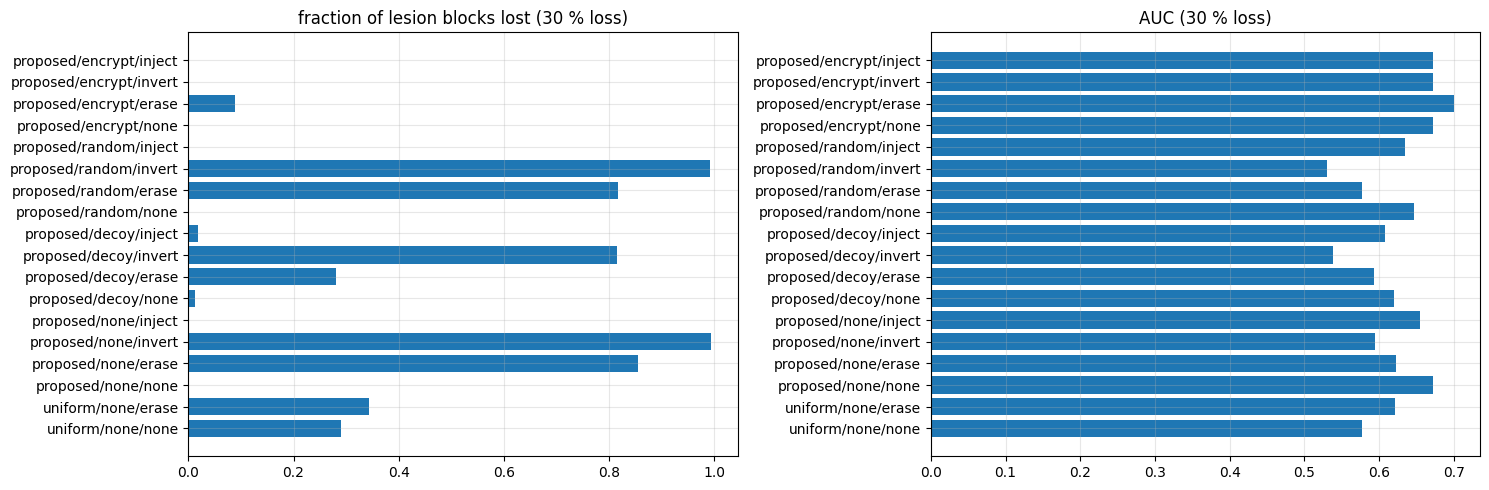

In [23]:
sub = B_res[(B_res.loss == .3) & (B_res.k.isin([0, K_TAG[-1]]))].copy()
sub["name"] = sub.strategy + "/" + sub.tag_defence + "/" + sub.attack
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, col, t in zip(ax, ("lesion_blocks_lost", "AUC"), ("fraction of lesion blocks lost (30 % loss)", "AUC (30 % loss)")):
    a.barh(sub.name, sub[col]); a.set_title(t); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(cfg.path("results", "adversarial_tags_v2.png"), dpi=130); plt.show()

## Part C. Combined: pixel attack (e2e PGD) + packet loss, uniform vs priority network
The attacker perturbs the image after the sender has computed the tags; the network then drops blocks.

In [24]:
NC = min(N_PIXEL, N); IC = np.arange(NC); impc = importance_sets(cfg, img01[:NC], list(H[:NC]), clf)
rows = []
for e in (0, 4, 8):
    base = img01[:NC] if e == 0 else adv_cache[("e2e", e)][:NC]
    for strat, src in (("uniform", "none"), ("proposed", "clinical")):
        for p in (0., .3, .5):
            dmg = np.stack([apply_loss(base[i], deliver(impc[src][i], strat, dict(p=p), np.random.default_rng(cfg.seed + i), cfg.burst_len)[0], cfg.block, cfg.recon)[0] for i in range(NC)])
            rows.append(dict(eps=e, strategy=strat, loss=p, **summ(ev(dmg), IC)))
C_res = pd.DataFrame(rows); C_res.to_csv(cfg.path("results", "adversarial_combined_v2.csv"), index=False); display(C_res.round(3))

,eps,strategy,loss,AUC,AUC_lo,AUC_hi,ACC,ASR,MMR,loc_hit
0,0,uniform,0.0,0.695,0.606,0.797,0.575,0.000,0.340,0.492
1,0,uniform,0.3,0.591,0.471,0.686,0.542,0.406,0.596,0.150
2,0,uniform,0.5,0.654,0.564,0.746,0.650,0.246,0.298,0.150
3,0,proposed,0.0,0.695,0.606,0.797,0.575,0.000,0.340,0.492
4,0,proposed,0.3,0.697,0.608,0.807,0.600,0.087,0.298,0.433
5,0,proposed,0.5,0.706,0.621,0.802,0.592,0.145,0.255,0.425
6,4,uniform,0.0,0.424,0.319,0.529,0.392,0.551,0.000,0.042
7,4,uniform,0.3,0.487,0.365,0.597,0.392,0.551,0.000,0.125
8,4,uniform,0.5,0.477,0.354,0.577,0.392,0.551,0.000,0.075
9,4,proposed,0.0,0.424,0.319,0.529,0.392,0.551,0.000,0.042


## Part D (optional). Adversarial fine-tuning of the classifier
Set `DO_AT = True` to fine-tune a copy of the classifier on PGD-perturbed training crops (ε = 4/255, lesion-centred crops) and re-measure the white-box `clf` attack.
This is a compact version (a few hundred steps); it trades some clean AUC for robustness, so compare both columns.

In [25]:
DO_AT = False
if DO_AT:
    import copy, torch.nn.functional as Fn
    from src.attack_v2 import crop_input
    from src.train_v2 import image_centres
    tr = images_df[(images_df.split == "train") & (~images_df.mixed)]; cen = image_centres(abn_df, len(images_df))
    clf_at = copy.deepcopy(clf).train()
    for p in clf_at.parameters(): p.requires_grad_(False)
    ps = [p for n, p in clf_at.named_parameters() if n.startswith(("bb.layer3", "bb.layer4", "D", "w"))]
    for p in ps: p.requires_grad_(True)
    opt = torch.optim.Adam(ps, 1e-5); rng = np.random.default_rng(0); alpha = float((tr.label == 0).sum() / (tr.label == 1).sum())
    for step in range(300):
        b = tr.sample(8, random_state=int(rng.integers(1e9)))
        x = T(np.stack([to01(images[i]) for i in b.img_idx])); hh = T(np.stack([np.asarray(heat[i], np.float32) for i in b.img_idx]))
        yy = torch.tensor(b.label.values, dtype=torch.float32, device=DEVICE); cc = cen[b.img_idx.values]
        clf_at.eval(); xa = attack("clf", x, yy.cpu().numpy(), hh, cc, None, localizers, clf_at, cfg, 4 / 255, 3); clf_at.train()
        w = torch.where(yy > 0, torch.full_like(yy, alpha), torch.ones_like(yy))
        loss = sum(Fn.binary_cross_entropy_with_logits(clf_at(crop_input(z, hh, cc, cfg))[2], yy, weight=w) for z in (x, xa)) / 2
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 50 == 0: print(step, float(loss))
    clf_at.eval(); [p.requires_grad_(False) for p in clf_at.parameters()]
    rec_at = ReceiverV2(cfg, localizers, clf_at, sigma=lm["sigma"]); rows = []
    for name, rc, cl in (("original", receiver, clf), ("adv-trained", rec_at, clf_at)):
        for e in (0, 4, 8):
            adv = img01[:N_PIXEL] if e == 0 else np.concatenate([attack("clf", T(img01[s:s + BS]), y[s:s + BS], T(H_t[s:s + BS]), c0[s:s + BS], None, localizers, cl, cfg, e / 255, STEPS)[:, 0].cpu().numpy() for s in range(0, N_PIXEL, BS)])
            r = diagnose_all(rc, adv); rows.append(dict(classifier=name, eps=e, AUC=auc_safe(y[:N_PIXEL], r["p"])))
    D_res = pd.DataFrame(rows); D_res.to_csv(cfg.path("results", "adversarial_training_v2.csv"), index=False); display(D_res.round(3))